<a href="https://colab.research.google.com/github/amarjankar24/Interships-Task-1/blob/main/task_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

local_file_path = '/content/superstore_sales.csv'

try:
    df = pd.read_csv(local_file_path, encoding='windows-1252')
except Exception as e:

    df = pd.read_csv(local_file_path, encoding='utf-8')

print("Dataset Shape:", df.shape)
print("\nDataset Columns & Types:")
df.info()


display(df.head())

Dataset Shape: (10800, 21)

Dataset Columns & Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 1

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


### 2. Data Cleaning and Processing
We will parse the order dates, check for missing values, and extract the Year-Month for monthly seasonality analysis.

In [9]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())

# Parse Order Date
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')

# Extract Year-Month
df['Year_Month'] = df['Order Date'].dt.to_period('M')

# Confirm the processing steps
display(df[['Order Date', 'Year_Month', 'Sales', 'Profit', 'Discount', 'Category']].head())

Missing values per column:
Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


,Order Date,Year_Month,Sales,Profit,Discount,Category
0,2017-11-08,2017-11,261.9600,41.9136,0.00,Furniture
1,2017-11-08,2017-11,731.9400,219.5820,0.00,Furniture
2,2017-06-12,2017-06,14.6200,6.8714,0.00,Office Supplies
3,2016-10-11,2016-10,957.5775,-383.0310,0.45,Furniture
4,2016-10-11,2016-10,22.3680,2.5164,0.20,Office Supplies


In [10]:
# 3. Aggregate Sales & Profit Analysis
# Grouping by Product Category, Region, and Customer Segment

agg_df = df.groupby(['Category', 'Region', 'Segment']).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Discount=('Discount', 'mean'),
    Order_Count=('Row ID', 'count')
).reset_index()

display(agg_df.head(10))

,Category,Region,Segment,Total_Sales,Total_Profit,Average_Discount,Order_Count
0,Furniture,Central,Consumer,86229.2190,-3994.4342,0.313569,255
1,Furniture,Central,Corporate,52085.6018,2321.9939,0.275912,137
2,Furniture,Central,Home Office,25482.3430,-1198.6091,0.284045,89
3,Furniture,East,Consumer,114211.8020,2038.1122,0.158086,303
4,Furniture,East,Corporate,64209.0460,342.1257,0.146970,198
5,Furniture,East,Home Office,29870.3560,665.9279,0.156000,100
6,Furniture,South,Consumer,70800.2040,4616.7326,0.111667,180
7,Furniture,South,Corporate,29645.0315,952.0303,0.151980,101
8,Furniture,South,Home Office,16853.4485,1202.4432,0.096078,51
9,Furniture,West,Consumer,119808.0870,4330.6680,0.130000,375


In [15]:
# Clean dataset by dropping fully null padding rows using .copy() to prevent warnings
df_cleaned = df.dropna(subset=['Order ID', 'Category', 'Sales', 'Profit']).copy()
print(f"Original rows: {len(df)}, Cleaned rows: {len(df_cleaned)}")

# Recalculate monthly seasonality data cleanly
df_cleaned['Order Date'] = pd.to_datetime(df_cleaned['Order Date'])
df_cleaned['Year_Month'] = df_cleaned['Order Date'].dt.to_period('M')
monthly_trend = df_cleaned.groupby('Year_Month')[['Sales', 'Profit']].sum().reset_index()
monthly_trend['Year_Month_Str'] = monthly_trend['Year_Month'].astype(str)

Original rows: 10800, Cleaned rows: 9994


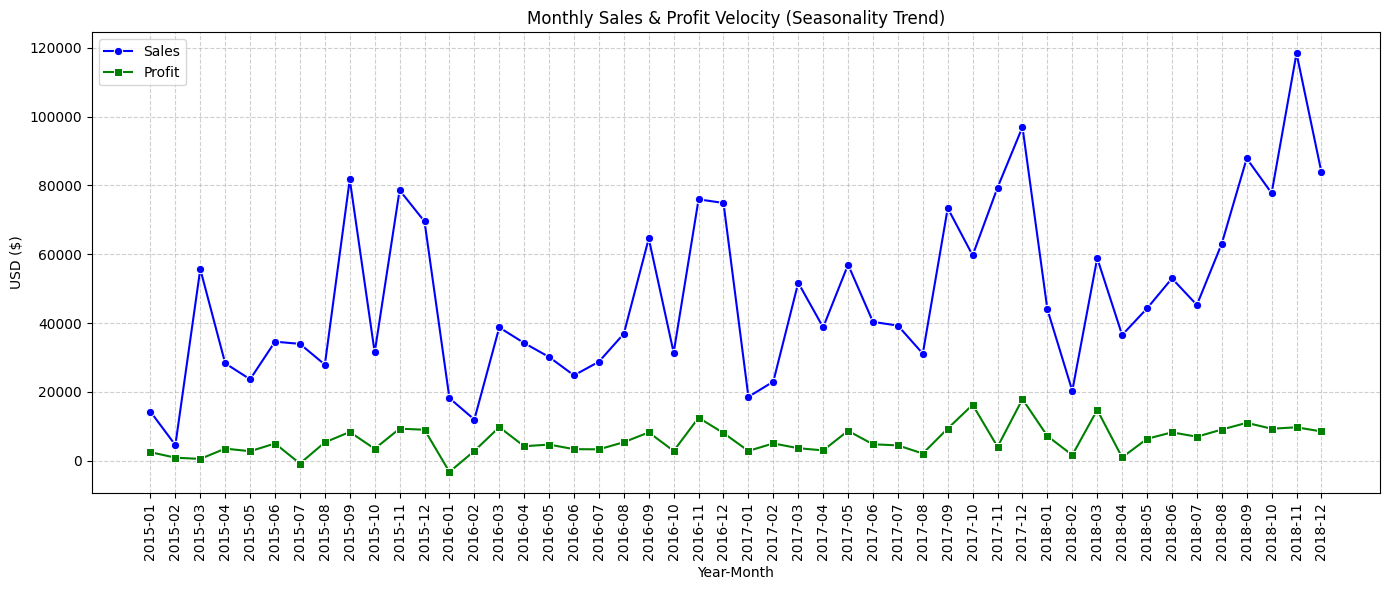

In [12]:
# 4. Plot Monthly Sales Velocity & Seasonality
plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_trend, x='Year_Month_Str', y='Sales', marker='o', label='Sales', color='blue')
sns.lineplot(data=monthly_trend, x='Year_Month_Str', y='Profit', marker='s', label='Profit', color='green')
plt.xticks(rotation=90)
plt.title("Monthly Sales & Profit Velocity (Seasonality Trend)")
plt.xlabel("Year-Month")
plt.ylabel("USD ($)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

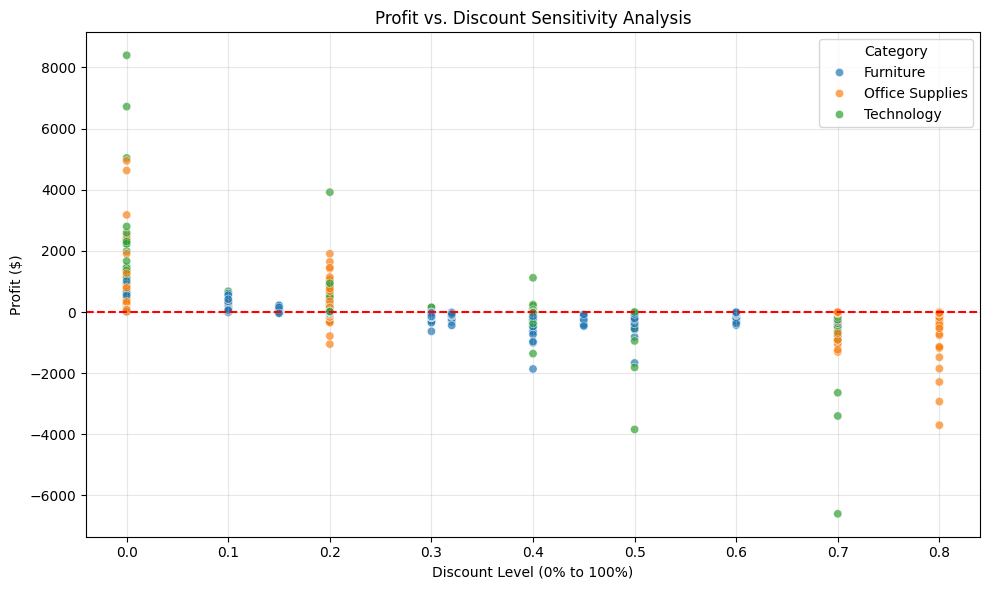

In [13]:
# 5. Plot Discount vs. Profit Sensitivity Scatter Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_cleaned, x='Discount', y='Profit', hue='Category', alpha=0.7)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5)
plt.title("Profit vs. Discount Sensitivity Analysis")
plt.xlabel("Discount Level (0% to 100%)")
plt.ylabel("Profit ($)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Executive Takeaways

1. **Holiday Seasonality Peak**: There is a clear recurring monthly surge in Sales and Profits during Q4 (specifically November and December) across multiple years, showing strong holiday seasonality.
2. **Discount Sensitivity Trap**: The scatter plot shows a steep negative impact on profits once discount rates exceed 20%. Offering high discounts frequently leads to severe, non-recoverable losses.
3. **Furniture Central Region Deficit**: Furniture sales in the Central region are operating at a net loss (Total Profit: -$3,994 for Consumers, -$1,198 for Home Office), strongly tied to high average discount rates (~31%).
4. **Technology Drives Profitability**: Technology consistently emerges as the highest profit-yielding category, maintaining robust margins even with moderate promotional activity.
5. **Corporate and Consumer Segment Stability**: Consumer and Corporate segments account for the bulk of consistent sales volume. Targeted non-discount loyalty perks could preserve margin health in these critical channels.